# 01 · Data and reference grid

Downloads the three core datasets, puts them on one Mars equirectangular grid
(IAU_2015:49910, ±30°, 1 km) and checks that everything lines up.

Conventions used everywhere: **planetocentric latitude, east-positive longitude (−180…180)**.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from marsgis import config as C, grid as G, criteria, overlay, ahp, validation, sensitivity, data, plots
grid = G.reference_grid()
C.FIGURES.mkdir(parents=True, exist_ok=True)
print(grid.shape, grid.crs)

(3556, 21338) IAU_2015:49910


## 1. Check that PROJ knows Mars

In [2]:
from pyproj import CRS
for code_ in (C.GEOG_CRS, C.PROJ_CRS):
    crs = CRS.from_user_input(code_)
    print(code_, '→', crs.name)
print(CRS.from_user_input(C.PROJ_CRS).to_proj4())

IAU_2015:49900 → Mars (2015) - Sphere / Ocentric
IAU_2015:49910 → Mars (2015) - Sphere / Ocentric / Equirectangular, clon = 0
+proj=eqc +lat_ts=0 +lat_0=0 +lon_0=0 +x_0=0 +y_0=0 +R=3396190 +units=m +no_defs +type=crs


## 2. Download and warp

Equivalent to `python scripts/download_data.py`. Set `QUICK = True` for a first pass
(DEM from its 4× overview, ~800 m, a few minutes); set it to `False` for the version you
publish (full 200 m read and averaged to 1 km; streams ~4 GB, or pass a local copy).

In [3]:
QUICK = False   # True = DEM from its 4x overview (~800 m) for a fast first pass
DEM_FILE = None   # e.g. C.RAW / 'Mars_HRSC_MOLA_BlendDEM_Global_200mp_v2.tif'

craters_csv = data.download_craters(C.RAW / 'robbins_craters_lat31.csv')
ti_geo = data.thermal_inertia_geotiff(C.RAW / 'ti_night_2007_geo.tif')
data.warp_to_grid(ti_geo, C.PROCESSED / 'ti_1km.tif', grid, resampling='bilinear')
if not (C.PROCESSED / 'dem_1km.tif').exists():
    data.warp_to_grid(data.dem_source(DEM_FILE), C.PROCESSED / 'dem_1km.tif', grid,
                      resampling='average', src_nodata=-32768, overview_level=1 if QUICK else None)

exists, skipping: robbins_craters_lat31.csv
exists, skipping: global_ti_night_2007.img


  ti_1km.tif: 25%  (1 s)


  ti_1km.tif: 50%  (2 s)


  ti_1km.tif: 75%  (3 s)


  ti_1km.tif: 100%  (4 s)


## 3. Inspect each layer: CRS, range, nodata, units

In [4]:
import rasterio
for name in ('dem_1km.tif', 'ti_1km.tif'):
    with rasterio.open(C.PROCESSED / name) as s:
        a = s.read(1, masked=True)
        print(f"{name}: {s.width}x{s.height}, {s.crs.to_string()[:40]}, nodata={s.nodata}, "
              f"min={a.min():.1f} median={np.ma.median(a):.1f} max={a.max():.1f}, nodata share={a.mask.mean():.4f}")
cr = pd.read_csv(craters_csv)
print(f"craters: {len(cr):,}, lon {cr.lon_e.min():.2f}…{cr.lon_e.max():.2f} (−180…180 ✓), "
      f"lat {cr.lat.min():.2f}…{cr.lat.max():.2f}, D ≥ {cr.diamkm.min()} km")

dem_1km.tif: 21338x3556, PROJCS["Mars (2015) - Sphere / Ocentric , nodata=-9999.0, min=-7070.7 median=135.1 max=21154.5, nodata share=0.0000


ti_1km.tif: 21338x3556, PROJCS["Mars (2015) - Sphere / Ocentric , nodata=-9999.0, min=5.0 median=190.8 max=4519.2, nodata share=0.0000


craters: 231,918, lon -180.00…180.00 (−180…180 ✓), lat -31.00…31.00, D ≥ 1.0 km


## 4. Alignment checks

rasters share shape, transform and CRS ✓


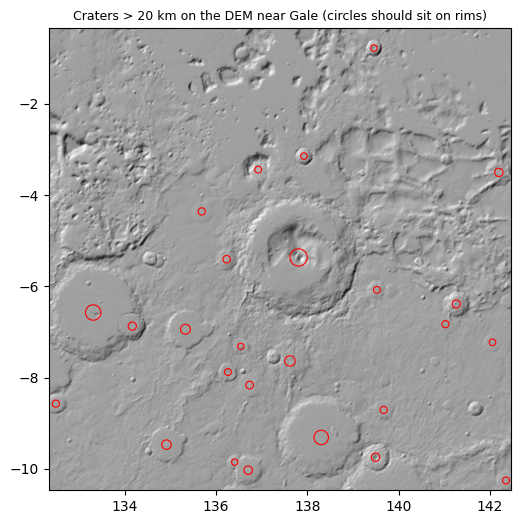

In [5]:
G.check_aligned([C.PROCESSED / 'dem_1km.tif', C.PROCESSED / 'ti_1km.tif'])
print('rasters share shape, transform and CRS ✓')

# Visual check: big craters should sit on DEM depressions (here around Gale).
dem, _ = G.read_raster(C.PROCESSED / 'dem_1km.tif')
r0, c0 = grid.lonlat_to_rowcol(137.4, -5.4)
win = dem[r0-300:r0+300, c0-300:c0+300]
lon0, lat0 = grid.rowcol_to_lonlat(r0-300, c0-300); lon1, lat1 = grid.rowcol_to_lonlat(r0+300, c0+300)
sub = cr[(cr.lon_e.between(lon0, lon1)) & (cr.lat.between(lat1, lat0)) & (cr.diamkm > 20)]
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(plots.hillshade(win, grid.res), cmap='gray', extent=[lon0, lon1, lat1, lat0])
ax.scatter(sub.lon_e, sub.lat, s=sub.diamkm, facecolors='none', edgecolors='r', lw=0.8)
ax.set_title('Craters > 20 km on the DEM near Gale (circles should sit on rims)', fontsize=9);

**Pitfalls checked here:** longitude convention (all three sources are −180…180 E, so no
shift is needed; `G.lon360_to_180` is there if you add a 0–360 dataset), DEM nodata
−32768 converted to NaN before any statistics, TES null (0) converted to NaN.